# 01 Explore the grid

Week 1 of *meter-trust*. This notebook:

1. loads the SimBench low-voltage feeder `1-LV-semiurb4--0-sw` and groups its customers into gateways,
2. runs an AC power flow for every 15-minute step of 4 weeks (2,688 steps),
3. places the meters (transformer P/Q/V, every customer P/Q, one voltage per feeder end),
4. runs weighted least squares (WLS) state estimation on sample steps and checks that the estimated voltages match the power flow within the measurement noise.

Everything here is simulation on a public test feeder, not utility data.

In [1]:
import sys, time
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp, simbench as sb

import grid, measurements as meas, estimation as est
print("pandapower", pp.__version__, "| simbench", sb.__version__)

pandapower 3.5.6 | simbench 1.6.3


## 1. The feeder and its gateways

In [2]:
net = grid.load_net()
lv_bus = net.trafo.lv_bus.iat[0]
summary = pd.Series({
    "buses": len(net.bus), "lines": len(net.line), "customers (loads)": len(net.load),
    "PV units": len(net.sgen), "transformer (MVA)": net.trafo.sn_mva.iat[0],
    "total line length (km)": round(net.line.length_km.sum(), 2),
})
display(summary.to_frame("value"))
display(net.load.groupby("gateway").agg(customers=("bus", "size"),
                                       peak_kW=("p_mw", lambda s: round(s.sum() * 1e3))))
display(net.load.profile.str.split("-").str[0].value_counts().rename("load profile type"))

,value
buses,44.00
lines,42.00
customers (loads),41.00
PV units,1.00
transformer (MVA),0.40
total line length (km),0.75


,customers,peak_kW
gateway,,
GW1,27,112
GW2,6,23
GW3,8,108


profile
H0    32
G1     3
G4     3
G2     2
G6     1
Name: load profile type, dtype: int64

Each gateway (data concentrator) serves one feeder leaving the transformer busbar, so customers behind the same gateway also share a cable. That matters in Week 2: a correlated gateway outage silences neighbours that the peer check relies on.

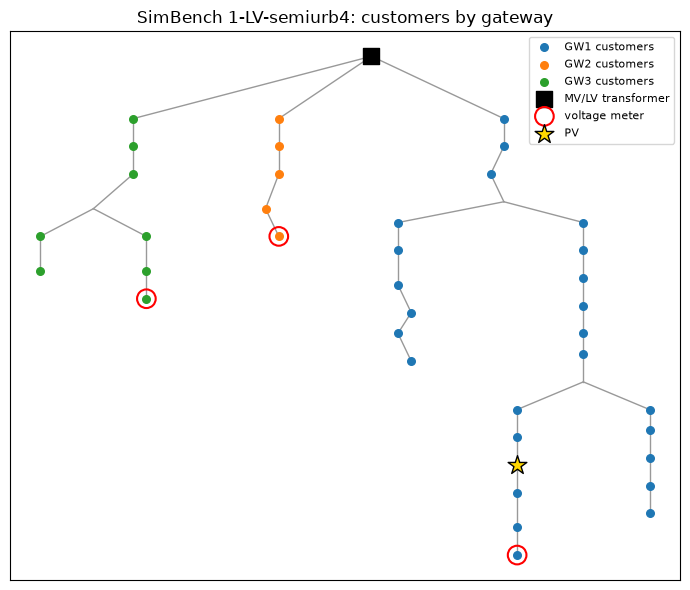

In [3]:
xy = net.bus.geo.map(lambda g: json.loads(g)["coordinates"])
x, y = xy.str[0], xy.str[1]
colors = {"GW1": "tab:blue", "GW2": "tab:orange", "GW3": "tab:green"}
bus_gw = pd.concat([net.load[["bus", "gateway"]], net.sgen[["bus", "gateway"]]]).drop_duplicates("bus").set_index("bus").gateway

fig, ax = plt.subplots(figsize=(7, 6))
for _, ln in net.line.iterrows():
    ax.plot([x[ln.from_bus], x[ln.to_bus]], [y[ln.from_bus], y[ln.to_bus]], color="0.6", lw=1, zorder=1)
for gw, c in colors.items():
    b = bus_gw.index[bus_gw == gw]
    ax.scatter(x[b], y[b], s=30, color=c, label=f"{gw} customers", zorder=2)
ax.scatter(x[lv_bus], y[lv_bus], marker="s", s=120, color="k", label="MV/LV transformer", zorder=3)
defs = meas.define_measurements(net)
vbus = defs.query("meas_type == 'v' and gateway != 'TRAFO'").element
ax.scatter(x[vbus], y[vbus], marker="o", s=180, facecolors="none", edgecolors="red", lw=1.5, label="voltage meter", zorder=4)
pv = net.sgen.bus
ax.scatter(x[pv], y[pv], marker="*", s=200, color="gold", edgecolors="k", label="PV", zorder=5)
ax.set_title("SimBench 1-LV-semiurb4: customers by gateway"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="best", fontsize=8); fig.tight_layout(); fig.savefig(FIG / "feeder.png", dpi=150)

## 2. Four weeks of 15-minute power flow

SimBench gives one year of normalised profiles starting 1 Jan 2016. `grid.get_profiles` turns them into absolute MW/Mvar and keeps the first 28 days.

In [4]:
profiles = grid.get_profiles(net, n_days=28)
t0 = time.time()
res = grid.run_power_flow_series(net, profiles)
grid.save_results(res)   # data/pf/*.parquet (gitignored, regenerated here)
print(f"{len(res['res_bus.vm_pu'])} steps in {time.time() - t0:.0f} s")

2688 steps in 16 s


LV voltage range 1.0019-1.0242 pu; peak feeder load 125 kW


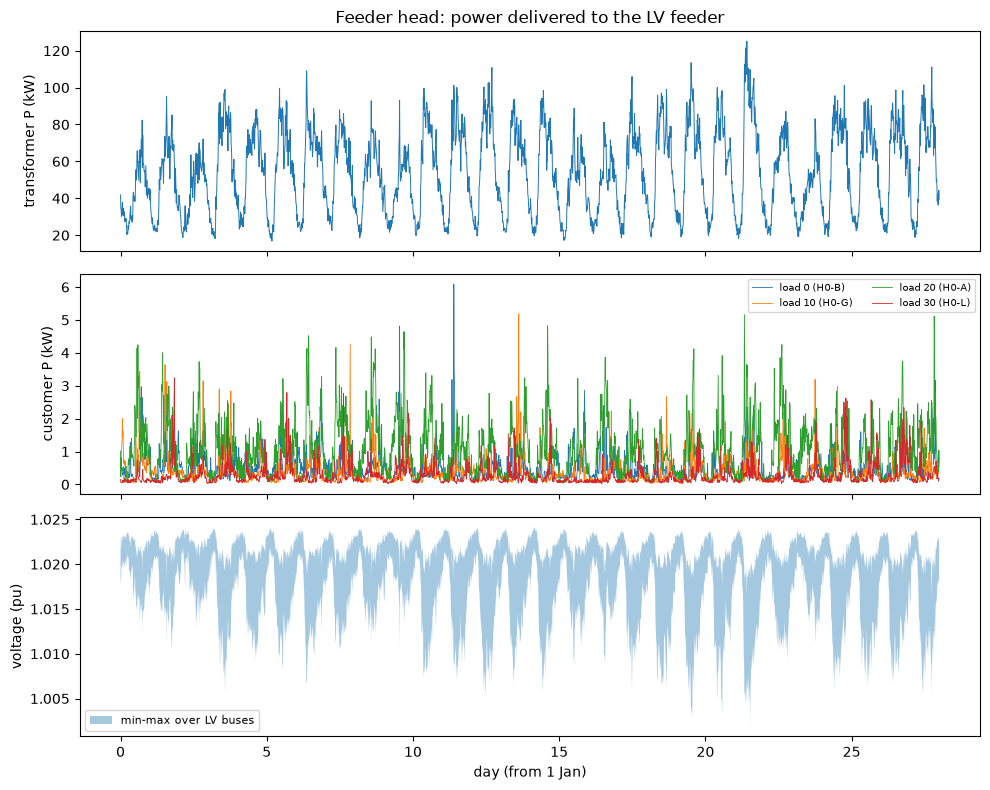

In [5]:
days = np.arange(len(res["res_bus.vm_pu"])) / grid.STEPS_PER_DAY
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axs[0].plot(days, res["res_trafo.p_lv_mw"].iloc[:, 0].mul(-1e3), lw=0.7)
axs[0].set_ylabel("transformer P (kW)"); axs[0].set_title("Feeder head: power delivered to the LV feeder")
for i in net.load.index[:: max(1, len(net.load) // 4)][:4]:
    axs[1].plot(days, res["res_load.p_mw"][i] * 1e3, lw=0.6, label=f"load {i} ({net.load.profile[i]})")
axs[1].set_ylabel("customer P (kW)"); axs[1].legend(fontsize=7, ncol=2)
vm = res["res_bus.vm_pu"].drop(columns=net.trafo.hv_bus.iat[0])
axs[2].fill_between(days, vm.min(axis=1), vm.max(axis=1), alpha=0.4, label="min-max over LV buses")
axs[2].set_ylabel("voltage (pu)"); axs[2].set_xlabel("day (from 1 Jan)"); axs[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "load_profiles.png", dpi=150)
print(f"LV voltage range {vm.min().min():.4f}-{vm.max().max():.4f} pu; "
      f"peak feeder load {res['res_trafo.p_lv_mw'].iloc[:, 0].mul(-1e3).max():.0f} kW")

The transformer column `p_lv_mw` is negative because pandapower counts power flowing *into* the transformer at that side; the plot flips the sign. Voltages stay within about 2 % of the 1.025 pu source: the feeder is lightly loaded in winter and the PV unit is small.

## 3. Measurements

| Meter | Quantity | Std (relative, floor) |
|---|---|---|
| Transformer LV side | P, Q, V | 0.5 % (floor 100 W); V 0.5 % |
| Every customer bus | P, Q injection | 1.5 % (floor 50 W) |
| Last bus of each feeder | V | 0.5 % |

Junction buses with no customer carry an exact zero-injection constraint. pandapower's estimator only reads bus, line and transformer measurements, so a customer meter is entered as a bus injection (two customers on one bus are summed).

In [6]:
display(defs.groupby(["group", "meas_type"]).size().rename("count").to_frame())
true = meas.true_values(defs, res)
std = meas.std_devs(defs, true)
noisy = meas.add_noise(true, std, seed=1)
print("measurements:", len(defs), "| zero-injection buses:", est.zero_injection_buses(net))

count
group       meas_type       
customer_pq p             39
            q             39
trafo_pq    p              1
            q              1
v           v              4

measurements: 84 | zero-injection buses: [1, 14, 17, 37]


## 4. WLS state estimation vs power flow

First a check with noise-free readings (the estimate should reproduce the power flow exactly), then every 12th step (every 3 hours, 224 steps) with noisy readings.

In [7]:
vm_pf = res["res_bus.vm_pu"]
sample = range(0, len(vm_pf), 12)

clean_err = []
for t in sample[::8]:
    e = est.run_wls(net, defs, true.loc[t], std.loc[t])
    clean_err.append((e.vm_pu - vm_pf.loc[t, e.index]).abs().max())
print(f"noise-free readings: max |V_est - V_pf| = {max(clean_err):.2e} pu over {len(clean_err)} steps")

rows, err, failed = [], [], 0
t0 = time.time()
for t in sample:
    e = est.run_wls(net, defs, noisy.loc[t], std.loc[t])
    if e is None:
        failed += 1; continue
    d = (e.vm_pu - vm_pf.loc[t, e.index])
    err.append(d.rename(t))
    c = est.chi2_test(net)
    rows.append({"t": t, "max_abs_dv": d.abs().max(), "mean_abs_dv": d.abs().mean(), **c})
err = pd.DataFrame(err)
steps = pd.DataFrame(rows).set_index("t")
print(f"{len(steps)} steps estimated, {failed} failed, {(time.time() - t0) / len(sample):.2f} s/step")

noise-free readings: max |V_est - V_pf| = 6.24e-10 pu over 28 steps


224 steps estimated, 0 failed, 0.06 s/step


In [8]:
v_std = meas.STD["v"][0]
report = pd.Series({
    "max |V_est - V_pf| (pu)": err.abs().max().max(),
    "mean |V_est - V_pf| (pu)": err.abs().stack().mean(),
    "std of V_est - V_pf (pu)": err.stack().std(),
    "voltage meter std (pu)": v_std,
    "share of errors within 1 meter std": (err.abs() <= v_std).stack().mean(),
    "chi2 dof": steps.dof.iat[0],
    "mean J (expected = dof)": steps.J.mean(),
    "chi2 false-alarm rate at 5 %": steps.flag.mean(),
}).to_frame("value")
report

,value
max |V_est - V_pf| (pu),0.006714
mean |V_est - V_pf| (pu),0.001996
std of V_est - V_pf (pu),0.002435
voltage meter std (pu),0.005000
share of errors within 1 meter std,0.946530
chi2 dof,5.000000
mean J (expected = dof),5.214210
chi2 false-alarm rate at 5 %,0.080357


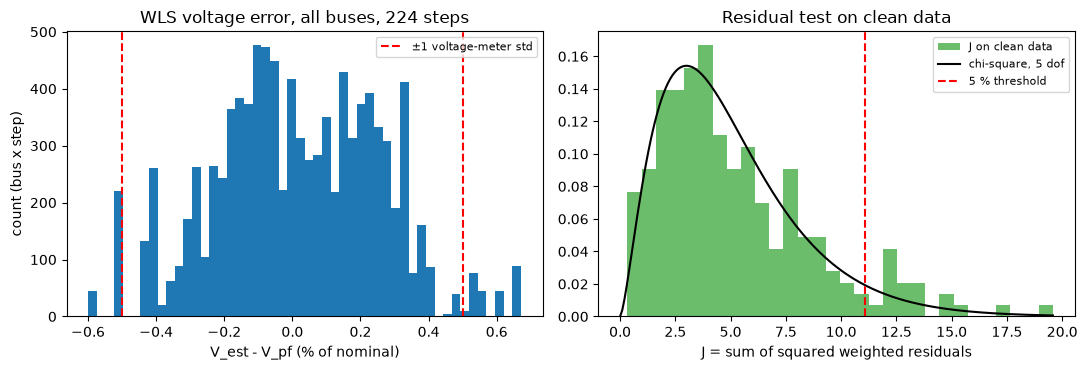

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(err.stack() * 100, bins=50, color="tab:blue")
axs[0].axvline(-v_std * 100, color="r", ls="--"); axs[0].axvline(v_std * 100, color="r", ls="--", label="±1 voltage-meter std")
axs[0].set_xlabel("V_est - V_pf (% of nominal)"); axs[0].set_ylabel("count (bus x step)"); axs[0].legend(fontsize=8)
axs[0].set_title("WLS voltage error, all buses, 224 steps")
axs[1].hist(steps.J, bins=30, density=True, color="tab:green", alpha=0.7, label="J on clean data")
from scipy.stats import chi2 as chi2_dist
jj = np.linspace(0, steps.J.max(), 200)
axs[1].plot(jj, chi2_dist.pdf(jj, steps.dof.iat[0]), "k", label=f"chi-square, {steps.dof.iat[0]} dof")
axs[1].axvline(steps.threshold.iat[0], color="r", ls="--", label="5 % threshold")
axs[1].set_xlabel("J = sum of squared weighted residuals"); axs[1].legend(fontsize=8)
axs[1].set_title("Residual test on clean data")
fig.tight_layout(); fig.savefig(FIG / "wls_vs_pf.png", dpi=150)

In [10]:
# How much of the error is a common voltage offset (the same at every bus)?
offset = err.mean(axis=1)
print(f"std of the per-step common offset: {offset.std():.4f} pu; "
      f"std after removing it: {err.sub(offset, axis=0).stack().std():.5f} pu")

std of the per-step common offset: 0.0024 pu; std after removing it: 0.00002 pu


## What this shows

- With noise-free readings WLS reproduces the power flow exactly, so the model, the measurement placement and the sign conventions are right.
- With noise, the voltage error is of the order of the voltage meters' own error (0.5 %). Almost all of it is a common offset across the feeder: only four voltage readings fix the overall voltage level, while the customer P/Q meters fix the voltage *differences* along the cables very precisely.
- The feeder has only about **5 degrees of freedom** of redundancy. The customer meters fix every injection; the only cross-checks are the transformer P/Q and the voltage readings. On clean data the chi-square statistic roughly follows its theoretical distribution (mean J 5.2 for 5 dof), but the false-alarm rate is 8 % on 224 steps against a nominal 5 %. That is about two standard errors high; Week 3 rechecks it on all steps before using the test as a baseline.
- That low redundancy is the point of the project. A single bad customer reading can only show up through the transformer balance, which the residual test sees as one number. It can say *something* is wrong, but not reliably *which* meter, and a consistent false-data attack that also keeps the transformer reading plausible would be invisible. Weeks 2-3 test this.

**pandapower 3.5.6 notes** (details in `src/estimation.py`): `zero_injection="no_inj_bus"` crashes on this net, so zero-injection buses are passed as a list; the estimator uses `wls_with_zero_constraint`, because plain `wls` treats the zero injections as 1 kW-std pseudo-measurements and the chi-square statistic runs low; and `chi2_analysis` / `remove_bad_data` drop the zero-injection setting internally, so the chi-square test is computed from the WLS residuals here.